# 07 · `TD_estado_LGBM_tw`: inventario y pronóstico contra real, XGBoost y ruta clásica

Continuación de `06_td_lightgbm.ipynb` (§7). En precisión, `TD_estado_LGBM_tw` (`TD_estado` con LightGBM Tweedie)
empató con `TD_estado` en prueba (WAPE 0.483 vs 0.482). Este notebook responde dos preguntas:

1. **Inventario:** ¿cuánto stock necesita cada pronóstico para dar el mismo servicio? Se usa la misma política y
   simulación de `03_inventario`: order-up-to mensual, SS empírico, venta perdida, `Media_post` para jóvenes,
   calentamiento y medición en validación (ene–jun 2025) y prueba (sep-2025 → sep-2026). Solo cambia el pronóstico de
   los SKUs maduros.
2. **Pronóstico contra real:** `TD_estado_LGBM_tw` frente a la venta real, XGBoost (`notebooks/XGBoost.py`, LOG #33) y
   la ruta clásica: en el top 30 de SKUs y familias (§2) y en **todos** los SKUs maduros, con XGBoost corrido para los
   mismos SKUs que los demás modelos (§3).
3. **Cierre (LOG #50):** el modelo se **adoptó**. §4 tiene la comparación final de todos los modelos en los mismos
   SKUs y §5 el pedido de sep-2026 con el modelo adoptado.

Código en `src/inventario_lgbm.py`. Completa el periodo puente (abr–may 2025), que la simulación necesita para tener
meses seguidos, con el mismo procedimiento de `td_lgbm.py`. Como control, la simulación de `TD_estado` reproduce
exactamente las cifras de `03_inventario` (`inv_simulacion.csv`). No se modifica nada de 01–06. En
`inventario.Insumos` solo se añadió un parámetro opcional (`extra`) para recibir un pronóstico externo.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from estilo import aplicar, COLORES, AZUL, GRIS, GRIS_CLARO, FMT_MILES
from metricas import resumen, adopta, por_origen
import comparar_xgb as cx

aplicar()
pd.set_option("display.width", 220, "display.max_columns", 40)
RES = RAIZ / "data" / "processed" / "resultados"
FIG = RAIZ / "reports" / "figuras"
TW = "TD_estado_LGBM_tw"
LL = ["id_articulo", "origen"]
PERIODOS = ["validacion", "prueba"]
COL = {"Real": "#0b0b0b", TW: AZUL, "TD_estado": GRIS, "XGBoost": COLORES[4], "Ruta_clasica": COLORES[1],
       "ML_base": COLORES[3]}

inv = pd.read_csv(RES / "inv_lgbm.csv")
ctrl = pd.read_csv(RES / "inv_simulacion.csv")
ctrl = ctrl[(ctrl.modelo == "TD_estado") & (ctrl.metodo == "empirico") & ~ctrl.nivel.astype(str).str.startswith("ABC")]
a = inv[(inv.modelo == "TD_estado") & (inv.metodo == "empirico")].assign(nivel=lambda x: x.nivel.round(2))
b = ctrl.assign(nivel=lambda x: x.nivel.astype(float).round(2))
chk = a.merge(b, on=["nivel", "periodo"], suffixes=("", "_03"))
assert len(chk) == 8 and np.allclose(chk.stock_prom_mxn, chk.stock_prom_mxn_03) and np.allclose(chk.fill_rate, chk.fill_rate_03)
print("Control: la simulación de TD_estado reproduce 03_inventario en", len(chk), "puntos (nivel × periodo)")

Control: la simulación de TD_estado reproduce 03_inventario en 8 puntos (nivel × periodo)


## 1. Inventario

### 1.1 Curva servicio–stock

Cada punto es una política con SS empírico uniforme (70 / 80 / 90 / 95 / 98 %). La que está **más arriba y a la
izquierda** da más servicio con menos stock. `ML_base` y la ruta clásica se muestran como contexto.

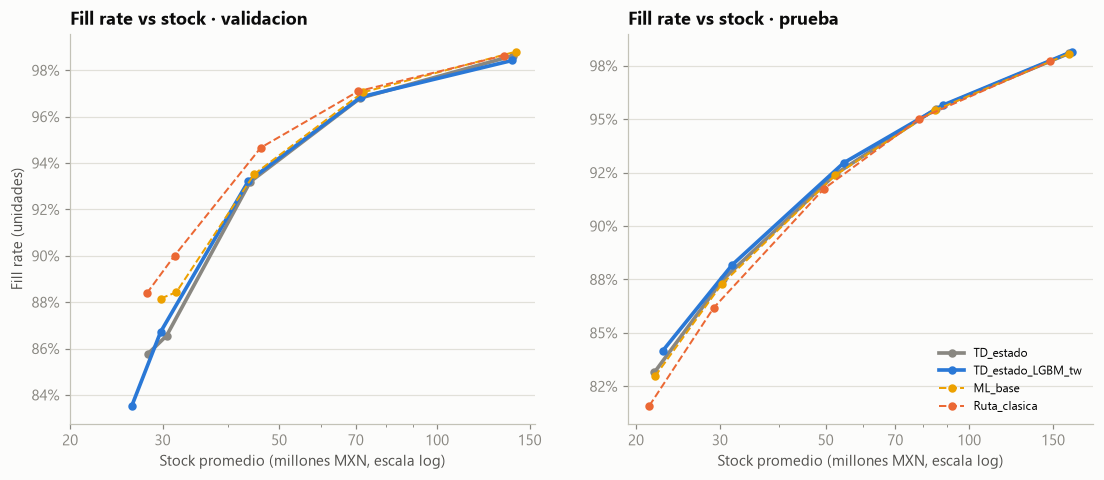

In [2]:
e = inv[inv.metodo == "empirico"]
MODS = ["TD_estado", TW, "ML_base", "Ruta_clasica"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for a, per in zip(ax, PERIODOS):
    for m in MODS:
        g = e[(e.periodo == per) & (e.modelo == m)].sort_values("fill_rate")
        a.plot(g.stock_prom_mxn / 1e6, g.fill_rate, marker="o", ms=4.5, color=COL[m],
               lw=2.4 if m in (TW, "TD_estado") else 1.3, ls="-" if m in (TW, "TD_estado") else "--", label=m)
    a.set_xscale("log")
    a.set_xticks([20, 30, 50, 70, 100, 150])
    a.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    a.xaxis.set_minor_formatter(plt.NullFormatter())
    a.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    a.set_xlabel("Stock promedio (millones MXN, escala log)")
    a.set_title(f"Fill rate vs stock · {per}")
ax[0].set_ylabel("Fill rate (unidades)")
ax[1].legend(fontsize=8, loc="lower right")
fig.savefig(FIG / "38_inv_lgbm_curva.png"); plt.show()

### 1.2 Stock a igual fill rate contra `TD_estado`

Para cada política se calcula el stock que necesitaría `TD_estado` para lograr **el mismo fill rate** (interpolación
log-lineal sobre su curva, como en `04_segmentacion`). Negativo = el modelo necesita menos stock que `TD_estado`.
`stock en riesgo` = valor al cierre de sep-2026 en SKUs sin venta en los últimos 6 meses.

In [3]:
filas = []
for per, g in e.groupby("periodo"):
    u = g[g.modelo == "TD_estado"].sort_values("fill_rate")
    for _, x in g.iterrows():
        eq = np.exp(np.interp(x.fill_rate, u.fill_rate, np.log(u.stock_prom_mxn)))
        fuera = not (u.fill_rate.min() <= x.fill_rate <= u.fill_rate.max())
        filas.append({"periodo": per, "modelo": x.modelo, "nivel": f"{x.nivel:.0%}", "fill": x.fill_rate,
                      "stock_M": x.stock_prom_mxn / 1e6, "cobertura_meses": x.cobertura_meses,
                      "venta_perdida_M": x.venta_perdida_mxn / 1e6,
                      "vs_TD_estado": np.nan if fuera else x.stock_prom_mxn / eq - 1,
                      "riesgo_M": x.stock_riesgo_mxn / 1e6})
comp = pd.DataFrame(filas)
for per in PERIODOS:
    t = comp[comp.periodo == per].set_index(["modelo", "nivel"]).drop(columns="periodo").reindex(MODS, level=0)
    if per == "validacion":
        t = t.drop(columns="riesgo_M")
    t["vs_TD_estado"] = t.vs_TD_estado.map(lambda v: "fuera de curva" if pd.isna(v) else f"{v:+.1%}")
    print(f"===== {per}")
    print(t.to_string(formatters={"fill": "{:.3f}".format, "stock_M": "{:.1f}".format, "cobertura_meses": "{:.2f}".format,
                                  "venta_perdida_M": "{:.2f}".format, "riesgo_M": "{:.2f}".format}))
    print()

===== validacion
                         fill stock_M cobertura_meses venta_perdida_M    vs_TD_estado
modelo            nivel                                                              
TD_estado         70%   0.858    28.1            2.15            2.14           -0.0%
                  80%   0.866    30.5            2.34            2.01           +0.0%
                  90%   0.932    44.0            3.37            1.23           +0.0%
                  95%   0.968    71.4            5.47            0.73           -0.0%
                  98%   0.986   139.7           10.70            0.31           +0.0%
TD_estado_LGBM_tw 70%   0.835    26.2            2.01            2.34  fuera de curva
                  80%   0.867    29.7            2.28            1.96           -3.5%
                  90%   0.932    43.7            3.35            1.20           -1.2%
                  95%   0.969    71.7            5.49            0.72           -1.5%
                  98%   0.984   138.9

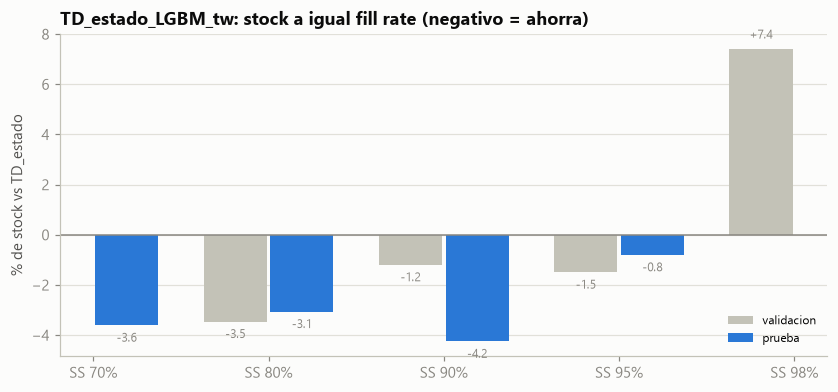

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.8))
niv = ["70%", "80%", "90%", "95%", "98%"]
x = np.arange(len(niv))
for i, (per, c) in enumerate(zip(PERIODOS, [GRIS_CLARO, AZUL])):
    v = comp[(comp.modelo == TW) & (comp.periodo == per)].set_index("nivel").vs_TD_estado.reindex(niv) * 100
    ax.bar(x + (i - .5) * .38, v.values, width=.36, color=c, label=per)
    for xi, vi in zip(x, v.values):
        if not np.isnan(vi):
            ax.text(xi + (i - .5) * .38, vi + (.3 if vi >= 0 else -.3), f"{vi:+.1f}", ha="center",
                    va="bottom" if vi >= 0 else "top", fontsize=8, color=GRIS)
ax.axhline(0, color=GRIS, lw=1)
ax.set_xticks(x, [f"SS {n}" for n in niv])
ax.set_ylabel("% de stock vs TD_estado")
ax.set_title(f"{TW}: stock a igual fill rate (negativo = ahorra)")
ax.legend(fontsize=8)
fig.savefig(FIG / "39_inv_lgbm_ahorro.png"); plt.show()

### 1.3 Lectura del inventario

- **En los niveles de uso real (80–95 %), `TD_estado_LGBM_tw` necesita 1–4 % menos stock que `TD_estado` para el
  mismo fill rate, en los dos periodos.** Al 90 % (el nivel recomendado en `03_inventario`) ahorra −1.2 % en
  validación y −4.2 % en prueba, unos 2 M MXN de stock promedio en prueba. Al 98 % se invierte en validación
  (+7.4 %; en prueba ese punto queda fuera de la curva de `TD_estado`), pero ese nivel no se usa.
- **Stock en riesgo** (sep-2026): menor en todos los niveles. Al 90 % es 2.43 vs 2.58 M MXN (−6 %), coherente con
  el menor sobre-pronóstico de Tweedie en los SKUs chicos.
- **Magnitud:** es una ventaja chica, del mismo orden que las diferencias que en LOG #28 y #45 se trataron como
  empate (±1–7 %). Lo nuevo es que **el signo es consistente** en los dos periodos y en los niveles 80–95 %. No
  es una mejora grande, pero tampoco es un empate puro.
- **Contexto:** la ruta clásica necesita 11–17 % menos stock en validación, pero en prueba queda igual o peor
  (−1 % a +6 %) y deja el mayor stock en riesgo (3.55 M MXN al 90 %, +38 %). Es el mismo patrón de LOG #28.

## 2. Pronóstico contra real: top 30 (único conjunto con XGBoost)

Mismos pares (SKU, origen) y mismas métricas de `02_modelos` §4.3. A nivel familia, cada pronóstico suma sus SKUs
maduros más los jóvenes (`Media_post`), igual que en `comparar_xgb.nivel_familia`. `TD_estado` se incluye como
referencia en las tablas.

In [5]:
M30 = [TW, "TD_estado", "Ruta_clasica", "XGBoost"]
assert cx.TD == TW                                  # comparar_xgb ya usa el modelo adoptado (LOG #50)
sku, (fam, _) = cx.nivel_sku(), cx.nivel_familia()
for p in PERIODOS:                                  # se agrega TD_estado (LOG #45) como referencia
    td = pd.read_parquet(RES / f"td_lgbm_{p}.parquet")
    sku[p] = sku[p].merge(td[LL + ["TD_estado"]], on=LL, validate="1:1")
    tf = td.groupby(["familia", "origen"]).TD_estado.sum().reset_index().rename(columns={"familia": "id_articulo"})
    fam[p] = fam[p].merge(tf, on=LL, how="left")
    fam[p]["TD_estado"] = fam[p].TD_estado.fillna(0) + fam[p].Media_post
for nivel, res in [("Top 30 SKUs", sku), ("Top 30 familias", fam)]:
    for p in PERIODOS:
        print(f"===== {nivel} · {p}  ({len(res[p])} pares SKU/familia × origen)")
        print(cx.tabla(res[p], M30).round(3).to_string()); print()

===== Top 30 SKUs · validacion  (360 pares SKU/familia × origen)
                    MASE   WAPE  sesgo      MAE      RMSE  sMAPE     R2
TD_estado_LGBM_tw  0.737  0.323  0.100  623.474   924.553  0.346  0.622
TD_estado          0.778  0.342  0.161  659.759   970.795  0.358  0.583
Ruta_clasica       0.723  0.318  0.133  614.338   903.806  0.352  0.639
XGBoost            0.989  0.460  0.246  889.035  2452.477  0.402 -1.661

===== Top 30 SKUs · prueba  (390 pares SKU/familia × origen)
                    MASE   WAPE  sesgo       MAE      RMSE  sMAPE     R2
TD_estado_LGBM_tw  0.956  0.399  0.042   778.048  1245.661  0.429  0.352
TD_estado          0.955  0.397  0.031   772.921  1234.771  0.428  0.363
Ruta_clasica       0.959  0.396  0.021   772.322  1217.133  0.432  0.381
XGBoost            1.314  0.604  0.262  1176.510  3243.730  0.496 -3.393

===== Top 30 familias · validacion  (360 pares SKU/familia × origen)
                    MASE   WAPE  sesgo       MAE      RMSE  sMAPE     R2
TD_es

**Lectura.**
- **Contra XGBoost:** `TD_estado_LGBM_tw` gana con amplitud en los cuatro cortes. En prueba, WAPE 0.399 vs 0.604
  (SKUs) y 0.225 vs 0.319 (familias), con sesgo de +4 % / +1 % contra +26 % / +14 %. XGBoost tiene R² negativo en
  SKUs: su error es mayor que el de predecir la media real del periodo (ver `02_modelos` §4.4).
- **Contra la ruta clásica:** en el top 30 empatan (WAPE 0.323 vs 0.318 y 0.399 vs 0.396 en SKUs; 0.245 vs 0.248 y
  0.225 vs 0.228 en familias). En los SKUs grandes, los suavizados clásicos ya son buenos. La ventaja del ML está en
  la cola de SKUs chicos e intermitentes (set completo, §3).
- **Contra `TD_estado`:** mejor en validación y apenas peor en prueba, igual que en el set completo.

### 2.1 Total mensual del top 30

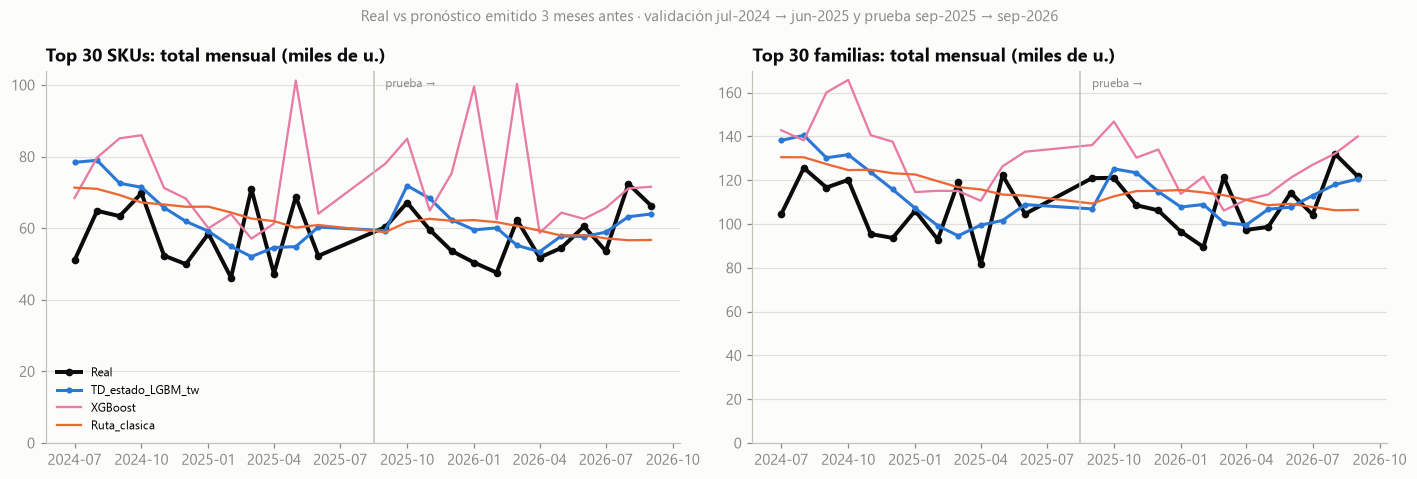

In [6]:
M3 = [TW, "XGBoost", "Ruta_clasica"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
for a, (nivel, res) in zip(ax, [("Top 30 SKUs", sku), ("Top 30 familias", fam)]):
    d = pd.concat(res.values())
    tot = d.groupby("mes_obj")[["y"] + M3].sum() / 1e3
    a.plot(tot.index, tot.y, color=COL["Real"], lw=2.6, marker="o", ms=4, label="Real")
    for m in M3:
        a.plot(tot.index, tot[m], color=COL[m], lw=2 if m == TW else 1.5, marker="o" if m == TW else None, ms=3, label=m)
    a.axvline(pd.Timestamp("2025-08-16"), color=GRIS_CLARO, lw=1)
    a.text(pd.Timestamp("2025-09-01"), a.get_ylim()[1] * .98, "prueba →", fontsize=8, color=GRIS, va="top")
    a.set_ylim(0, None)
    a.set_title(f"{nivel}: total mensual (miles de u.)")
ax[0].legend(fontsize=8, loc="lower left")
fig.suptitle("Real vs pronóstico emitido 3 meses antes · validación jul-2024 → jun-2025 y prueba sep-2025 → sep-2026",
             fontsize=9.5, color=GRIS)
fig.tight_layout()
fig.savefig(FIG / "40_top30_tw_xgb_ruta_total.png"); plt.show()

### 2.2 Por SKU (top 30)

Ordenados por venta en prueba. La escala vertical es propia de cada panel.

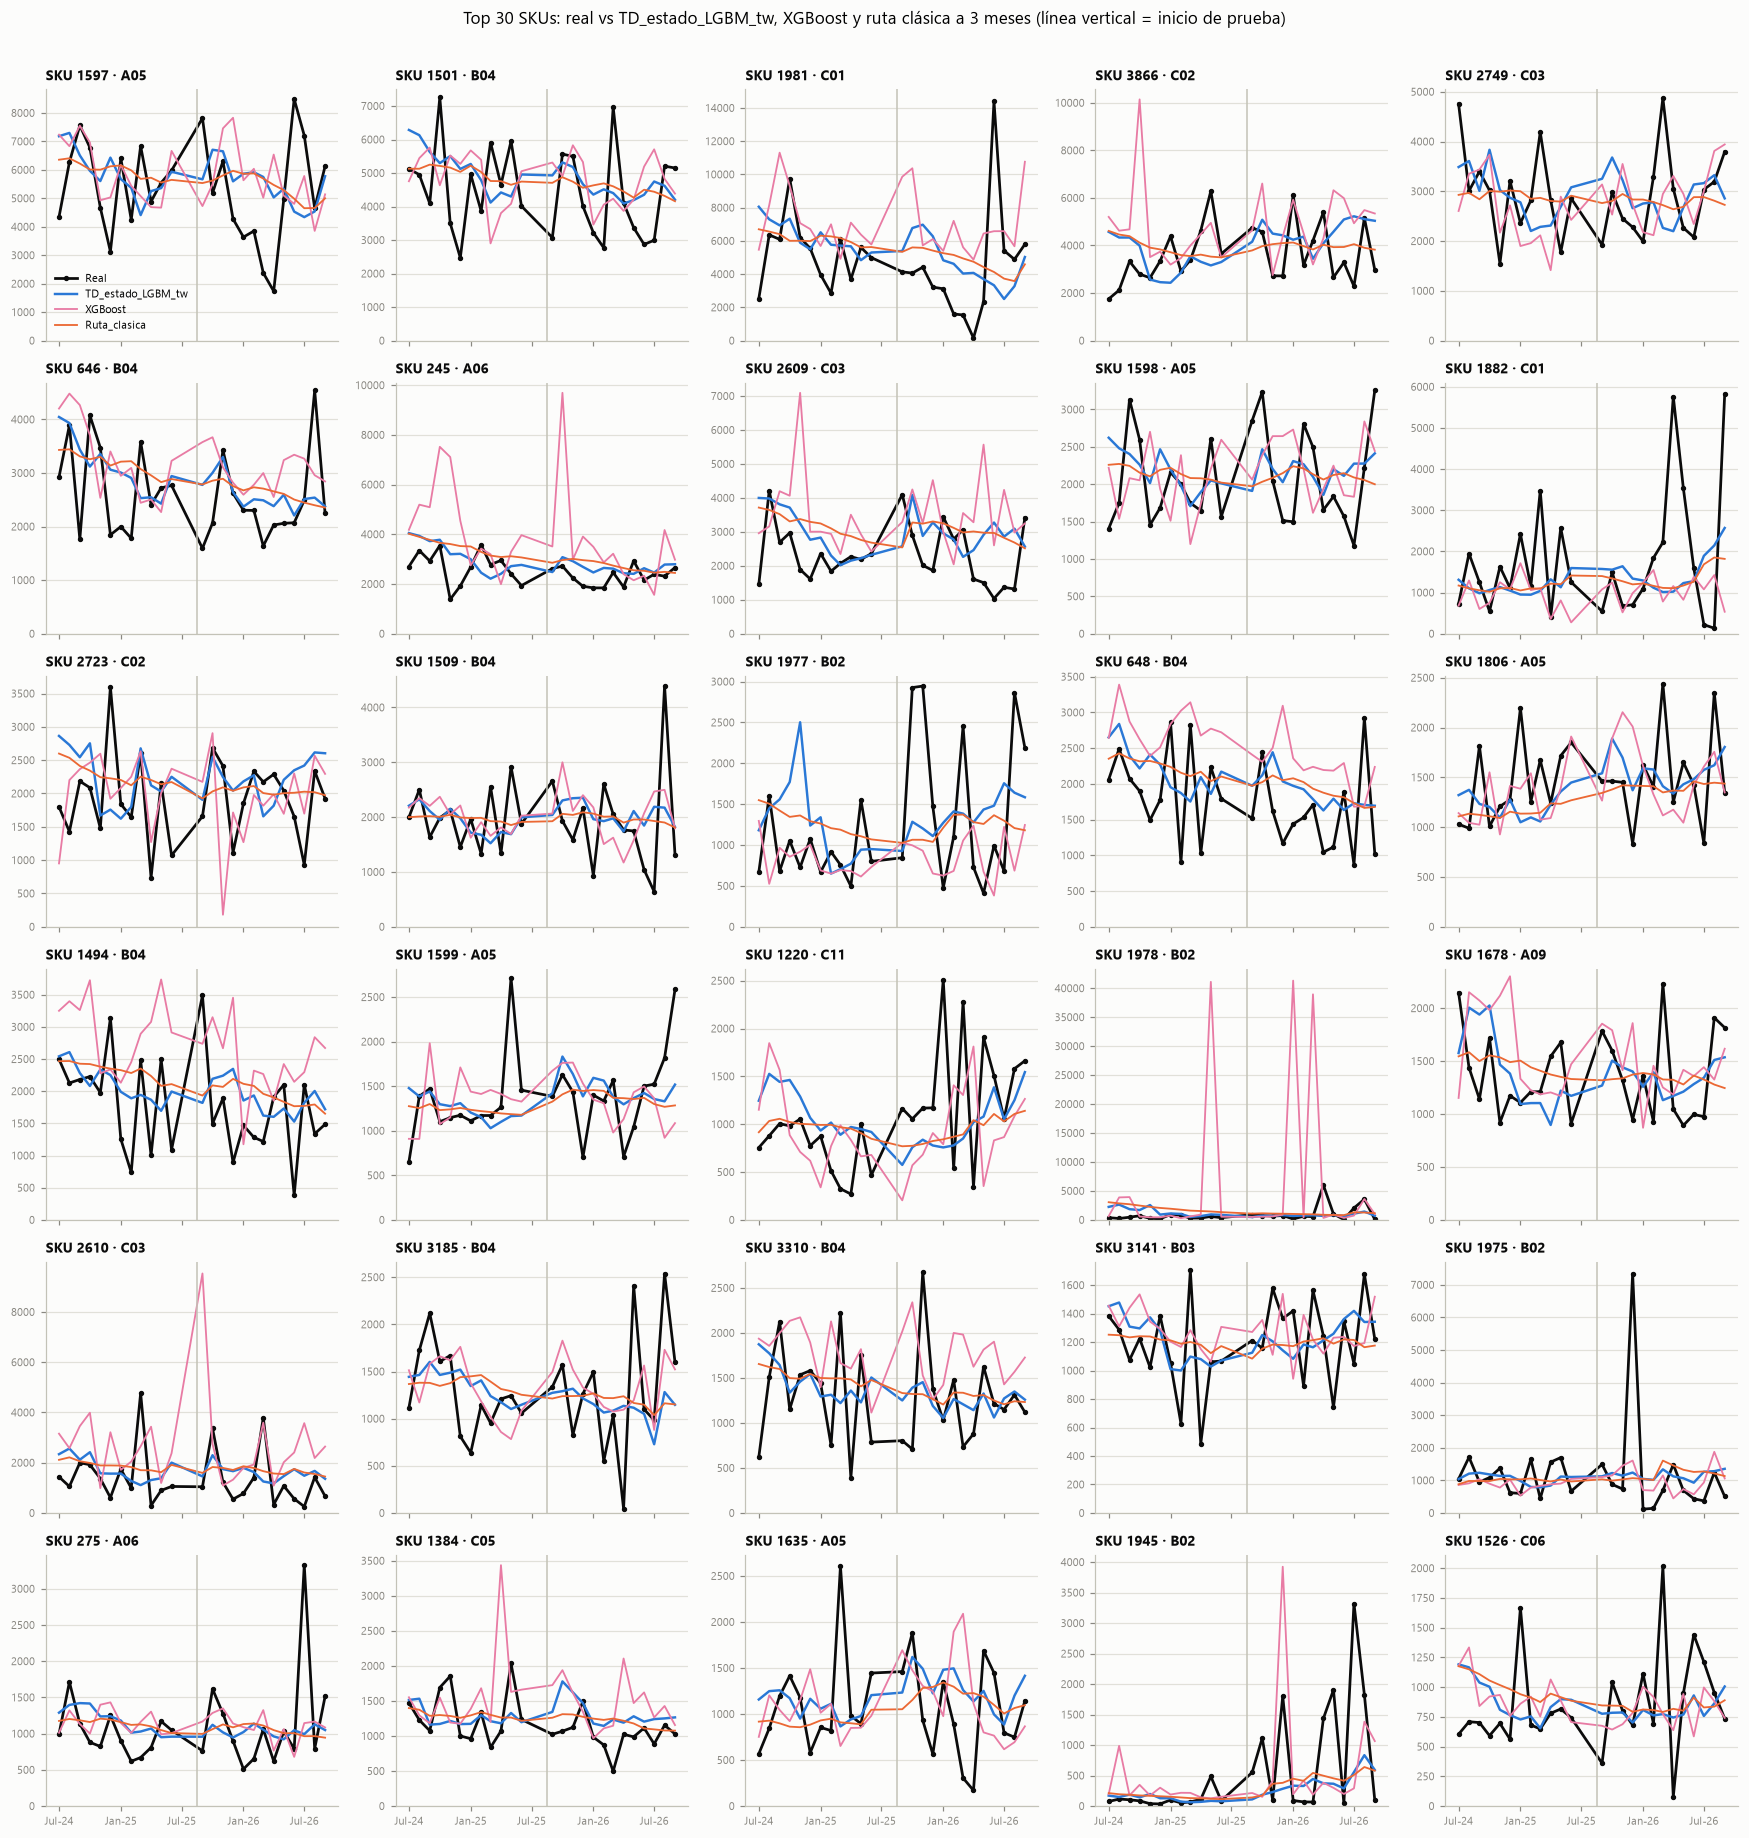

In [7]:
d = pd.concat(sku.values())
orden = d[d.mes_obj >= "2025-10-01"].groupby("id_articulo").y.sum().sort_values(ascending=False).index
fig, ax = plt.subplots(6, 5, figsize=(16, 17), sharex=True)
for a, s in zip(ax.ravel(), orden):
    g = d[d.id_articulo == s].sort_values("mes_obj")
    a.plot(g.mes_obj, g.y, color=COL["Real"], lw=1.8, marker="o", ms=2.5, label="Real")
    for m in M3:
        a.plot(g.mes_obj, g[m], color=COL[m], lw=1.6 if m == TW else 1.2, label=m)
    a.axvline(pd.Timestamp("2025-08-16"), color=GRIS_CLARO, lw=1)
    a.set_ylim(0, None)
    a.set_title(f"SKU {s} · {g.familia.iloc[0]}", fontsize=9)
    a.tick_params(labelsize=7)
    a.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    a.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
ax[0, 0].legend(fontsize=7)
fig.suptitle("Top 30 SKUs: real vs TD_estado_LGBM_tw, XGBoost y ruta clásica a 3 meses (línea vertical = inicio de prueba)", fontsize=11)
fig.tight_layout(rect=[0, 0, 1, .975])
fig.savefig(FIG / "41_top30_tw_xgb_ruta_por_sku.png"); plt.show()

In [8]:
p = sku["prueba"]
err = p.assign(**{m: (p[m] - p.y).abs() for m in M3}).groupby("id_articulo")[M3].sum()
mejor = err.idxmin(axis=1).value_counts()
print("Top 30 SKUs, prueba: modelo con menor error absoluto acumulado por SKU")
print(mejor.reindex(M3).fillna(0).astype(int).to_string())

Top 30 SKUs, prueba: modelo con menor error absoluto acumulado por SKU
TD_estado_LGBM_tw    13
XGBoost               6
Ruta_clasica         11


SKU por SKU en prueba, `TD_estado_LGBM_tw` tiene el menor error acumulado en 13 de los 30, la ruta clásica en 11 y
XGBoost en 6. XGBoost acierta en algunos SKUs, pero cuando falla lo hace por mucho (RMSE 2.6× el de los demás).

## 3. Set completo de SKUs maduros: real vs `TD_estado_LGBM_tw`, XGBoost y ruta clásica

Todos los SKUs evaluados. XGBoost se corrió para todos ellos con el mismo script del usuario (un modelo por SKU,
mes + lags 3/4/5), en exactamente los mismos pares (SKU, origen) que los demás modelos (`src/xgb_todos.py`). Como
control, en el top 30 reproduce los pronósticos de `xgb_top30_sku.parquet`. Si un par no tiene pronóstico XGBoost
porque la historia no alcanza, se excluye de la comparación para todos los modelos.

validacion: 9416 pares, 0 sin XGBoost (excluidos)
prueba: 10301 pares, 0 sin XGBoost (excluidos)


===== validacion
                    WAPE  sesgo   MASE  WAPE_total  sesgo_total gana vs Ruta cumple vs Ruta
TD_estado_LGBM_tw  0.436  0.093  0.703       0.165        0.093         9/12           True
TD_estado          0.456  0.152  0.771       0.204        0.152         6/12          False
Ruta_clasica       0.459  0.152  0.825       0.168        0.152                            
XGBoost            0.594  0.244  0.918       0.261        0.244         0/12          False
ML_base            0.469  0.193  0.788       0.223        0.193         6/12          False



===== prueba
                    WAPE  sesgo   MASE  WAPE_total  sesgo_total gana vs Ruta cumple vs Ruta
TD_estado_LGBM_tw  0.483  0.020  0.924       0.094        0.020         9/13           True
TD_estado          0.482  0.016  0.942       0.087        0.016        11/13           True
Ruta_clasica       0.497  0.017  0.953       0.112        0.017                            
XGBoost            0.681  0.212  1.130       0.212        0.212         0/13          False
ML_base            0.490  0.035  0.952       0.099        0.035         7/13          False



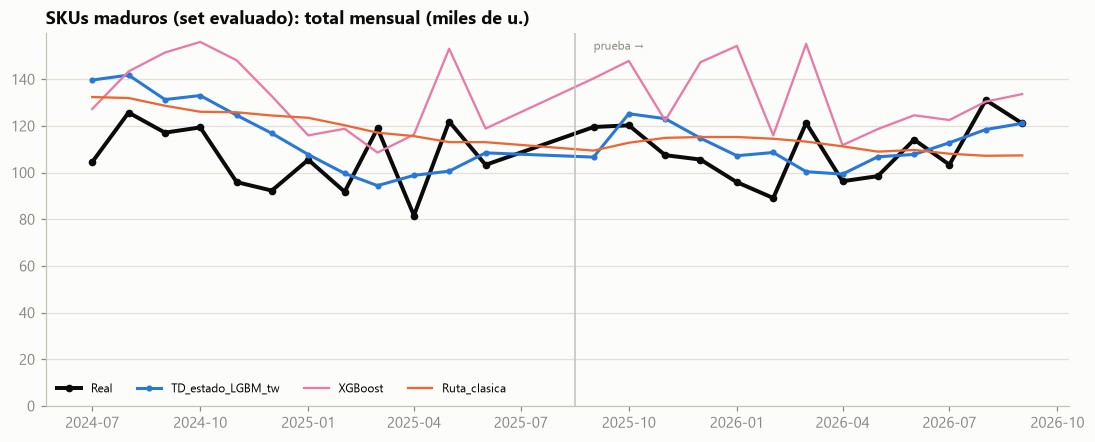

In [9]:
full = {}
for p in PERIODOS:
    x = pd.read_parquet(RES / f"td_lgbm_{p}.parquet").merge(pd.read_parquet(RES / f"xgb_todos_{p}.parquet"), on=LL, validate="1:1")
    print(f"{p}: {len(x)} pares, {x.XGBoost.isna().sum()} sin XGBoost (excluidos)")
    full[p] = x[x.XGBoost.notna()].copy()
for p in PERIODOS:
    x = full[p]
    r = resumen(x, [TW, "TD_estado", "Ruta_clasica", "XGBoost", "ML_base"])[["WAPE", "sesgo", "MASE", "WAPE_total", "sesgo_total"]]
    r["gana vs Ruta"] = ["" if m == "Ruta_clasica" else por_origen(x, [m, "Ruta_clasica"]).pipe(lambda z: f"{(z[m] < z.Ruta_clasica).sum()}/{len(z)}") for m in r.index]
    r["cumple vs Ruta"] = ["" if m == "Ruta_clasica" else adopta(x, m, "Ruta_clasica") for m in r.index]
    print(f"===== {p}"); print(r.round(3).to_string()); print()

d = pd.concat(full.values())
tot = d.groupby("mes_obj")[["y"] + M3].sum() / 1e3
fig, ax = plt.subplots(figsize=(12, 4.4))
ax.plot(tot.index, tot.y, color=COL["Real"], lw=2.6, marker="o", ms=4, label="Real")
for m in M3:
    ax.plot(tot.index, tot[m], color=COL[m], lw=2 if m == TW else 1.5, marker="o" if m == TW else None, ms=3, label=m)
ax.axvline(pd.Timestamp("2025-08-16"), color=GRIS_CLARO, lw=1)
ax.text(pd.Timestamp("2025-09-01"), ax.get_ylim()[1] * .98, "prueba →", fontsize=8, color=GRIS, va="top")
ax.set_ylim(0, None)
ax.set_title("SKUs maduros (set evaluado): total mensual (miles de u.)")
ax.legend(fontsize=8, ncol=4, loc="lower left")
fig.savefig(FIG / "42_set_tw_xgb_ruta_total.png"); plt.show()

- **Contra la ruta clásica:** en el set completo, `TD_estado_LGBM_tw` le gana en WAPE (0.436 vs 0.459 en
  validación y 0.483 vs 0.497 en prueba; 9/12 y 9/13 orígenes, cumple la regla) y en MASE (0.703 vs 0.825 y 0.924
  vs 0.953), con sesgo parecido en prueba (+2.0 vs +1.7 %). La ventaja que no aparece en el top 30 sale de la cola
  de SKUs medianos y chicos.
- **XGBoost en todos los SKUs** queda peor que en el top 30: WAPE 0.594 en validación y 0.681 en prueba, con sesgo
  de +24 % / +21 % y MASE > 1 en prueba (peor que el seasonal naive in-sample). No le gana a la ruta clásica en
  ningún origen. Un modelo por SKU con solo ~100 meses de historia y lags 3–5 sobreajusta. En los SKUs chicos e
  intermitentes, donde la serie es casi todo ceros y picos, ese sobreajuste es peor (LOG #33).

## 4. Comparación final: todos los modelos en los mismos SKUs

Tabla de cierre del proyecto. Incluye todos los modelos del backtest, los dos `TD_estado` y XGBoost, evaluados en las
mismas filas (SKU maduro, origen) del §3, ordenados por WAPE de prueba. `cumple vs adoptado` aplica la regla de
adopción con `TD_estado_LGBM_tw` como referencia. `True` significaría que ese modelo le gana al adoptado.

In [10]:
FIN = ["SNaive", "Naive", "MA12", "ETS", "Croston", "SBA", "TSB", "SARIMA_fam", "Ruta_clasica", "XGBoost",
       "ML_base", "L_tweedie", "TD_estado", TW]
cols = {}
for p in PERIODOS:
    x = full[p]
    r = resumen(x, FIN)[["WAPE", "sesgo", "MASE", "WAPE_total"]]
    r["gana_vs_adoptado"] = ["" if m == TW else por_origen(x, [m, TW]).pipe(lambda z: f"{(z[m] < z[TW]).sum()}/{len(z)}") for m in FIN]
    r["cumple_vs_adoptado"] = ["" if m == TW else adopta(x, m, TW) for m in FIN]
    cols[p] = r
final = pd.concat(cols, axis=1).sort_values(("prueba", "WAPE"))
print(final.round(3).to_string())
final.round(4).to_csv(RAIZ / "reports" / "comparacion_final_modelos.csv", encoding="utf-8-sig")

                  validacion                                                              prueba                                                             
                        WAPE  sesgo   MASE WAPE_total gana_vs_adoptado cumple_vs_adoptado   WAPE  sesgo   MASE WAPE_total gana_vs_adoptado cumple_vs_adoptado
TD_estado              0.456  0.152  0.771      0.204             3/12              False  0.482  0.016  0.942      0.087             4/13              False
TD_estado_LGBM_tw      0.436  0.093  0.703      0.165                                      0.483  0.020  0.924      0.094                                    
ML_base                0.469  0.193  0.788      0.223             4/12              False  0.490  0.035  0.952      0.099             3/13              False
L_tweedie              0.441  0.113  0.709      0.175             3/12              False  0.491  0.038  0.933      0.102             5/13              False
MA12                   0.482  0.201  0.831      0.21

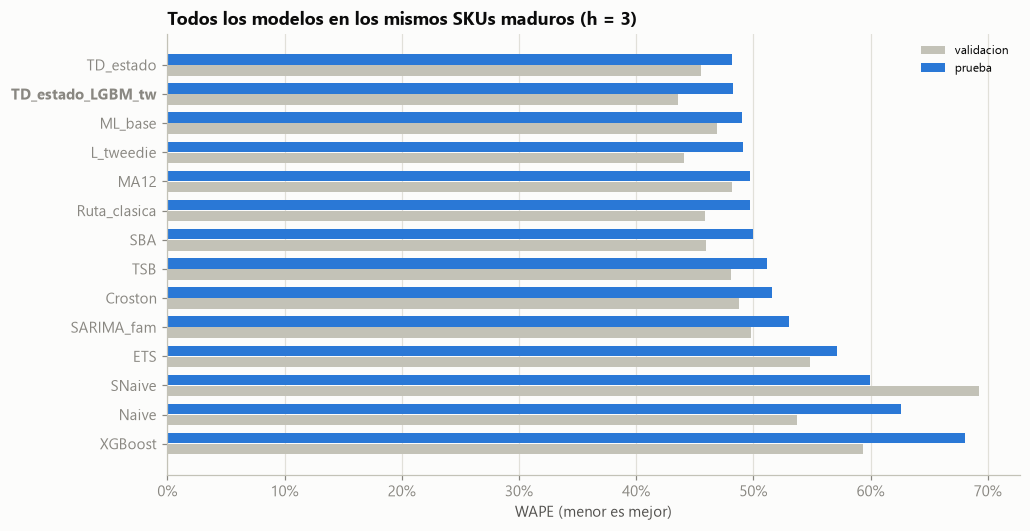

In [11]:
fig, ax = plt.subplots(figsize=(10, 5.2))
orden = final.index[::-1]
y = np.arange(len(orden))
for i, (p, c) in enumerate(zip(PERIODOS, [GRIS_CLARO, AZUL])):
    v = final[(p, "WAPE")].reindex(orden)
    ax.barh(y + (i - .5) * .38, v.values, height=.36, color=c, label=p)
ax.set_yticks(y, orden)
for t in ax.get_yticklabels():
    if t.get_text() == TW:
        t.set_fontweight("bold")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("WAPE (menor es mejor)")
ax.set_title("Todos los modelos en los mismos SKUs maduros (h = 3)")
ax.legend(fontsize=8, loc="upper right")
fig.savefig(FIG / "43_comparacion_final_wape.png"); plt.show()

## 5. Pedido con el modelo adoptado (sep-2026, ventana oct–dic 2026)

`src/pedido.py` ahora usa `TD_estado_LGBM_tw`: entrena LightGBM Tweedie en los orígenes jul–sep 2026 y aplica la
misma regla por estado de la familia. El SS empírico se calibra con los errores de ventana del modelo adoptado. El
pedido anterior (`TD_estado`, LOG #45) se conservó como `reports/pedido_recomendado_2026-09_TD_estado_LOG45.csv`.

In [12]:
nuevo = pd.read_csv(RAIZ / "reports" / "pedido_recomendado_2026-09.csv", index_col=0)
previo = pd.read_csv(RAIZ / "reports" / "pedido_recomendado_2026-09_TD_estado_LOG45.csv", index_col=0)
c = ["ventana", "ss_90", "S_90", "Q_90_max", "ss_95", "S_95", "Q_95_max"]
t = pd.DataFrame({"TD_estado (LOG #45)": previo[c].sum(), f"{TW} (adoptado)": nuevo[c].sum()})
t["diferencia"] = (t.iloc[:, 1] / t.iloc[:, 0] - 1).map("{:+.1%}".format)
print(f"SKUs: {len(nuevo)} (antes {len(previo)})")
print(t.to_string(formatters={k: "{:,.0f}".format for k in t.columns[:2]}))
print()
print("Ventana por clase (unidades):")
print(pd.DataFrame({"previo": previo.groupby("clase").ventana.sum(), "nuevo": nuevo.groupby("clase").ventana.sum()}).round(0).to_string())

SKUs: 906 (antes 906)
         TD_estado (LOG #45) TD_estado_LGBM_tw (adoptado) diferencia
ventana              344,878                      338,401      -1.9%
ss_90                224,098                      234,685      +4.7%
S_90                 568,978                      573,087      +0.7%
Q_90_max             416,440                      419,898      +0.8%
ss_95                393,438                      405,066      +3.0%
S_95                 738,319                      743,469      +0.7%
Q_95_max             562,236                      566,840      +0.8%

Ventana por clase (unidades):
                previo     nuevo
clase                           
errática      148090.0  145341.0
grumosa         4320.0    4109.0
intermitente     256.0     262.0
joven           2476.0    2476.0
suave         189735.0  186214.0


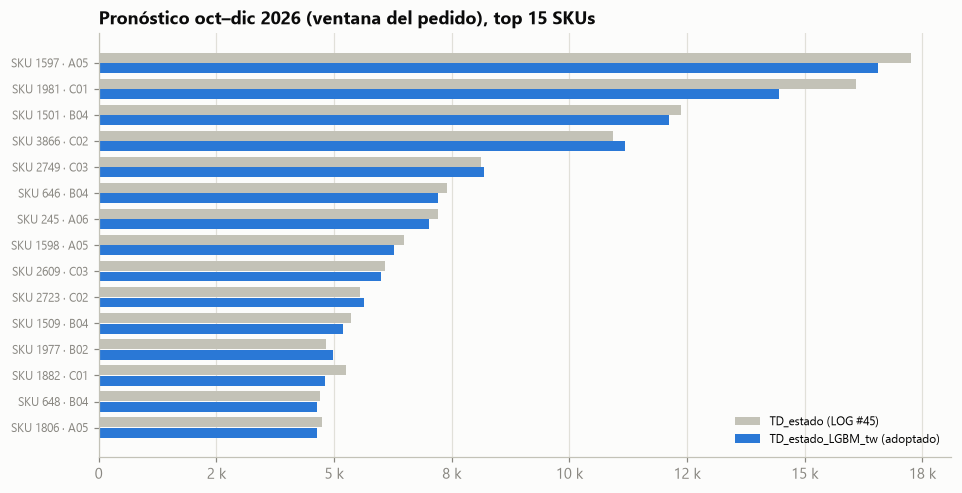

In [13]:
top = nuevo.nlargest(15, "ventana")
fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(top))[::-1]
ax.barh(y + .2, previo.ventana.reindex(top.index), height=.38, color=GRIS_CLARO, label="TD_estado (LOG #45)")
ax.barh(y - .2, top.ventana, height=.38, color=AZUL, label=f"{TW} (adoptado)")
ax.set_yticks(y, [f"SKU {s} · {f}" for s, f in zip(top.index, top.familia)], fontsize=8)
ax.xaxis.set_major_formatter(FMT_MILES)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Pronóstico oct–dic 2026 (ventana del pedido), top 15 SKUs")
ax.legend(fontsize=8, loc="lower right")
fig.savefig(FIG / "44_pedido_tw_vs_previo.png"); plt.show()

## 6. Hallazgos y decisión

1. **Inventario:** `TD_estado_LGBM_tw` necesita **1–4 % menos stock** que `TD_estado` a igual fill rate en los
   niveles 80–95 %, en validación y en prueba. Al 90 % el ahorro es −1.2 % / −4.2 %, y el stock en riesgo es 6 % menor.
   La ventaja es chica, pero va en la misma dirección en los dos periodos.
2. **Contra XGBoost:** gana con amplitud en el top 30 (WAPE 0.40 vs 0.60 en SKUs de prueba; sesgo +4 % vs +26 %) y
   en todos los SKUs maduros (0.483 vs 0.681 en prueba; sesgo +2 % vs +21 %). En el set completo, XGBoost es el
   peor de los 14 modelos en prueba.
3. **Contra la ruta clásica:** empata en el top 30 (SKUs grandes) y gana en el set completo (−1.4 pp de WAPE en
   prueba, 9/13 orígenes, MASE 0.924 vs 0.953). En inventario, la ruta no es consistente entre periodos y deja más
   stock en riesgo.
4. **Comparación final (§4):** ningún modelo cumple la regla contra `TD_estado_LGBM_tw` en ningún periodo. Solo
   `TD_estado` lo iguala en prueba (0.482 vs 0.483).
5. **Balance frente a `TD_estado`:** precisión igual en prueba, mejor en validación (0.436 vs 0.456), mejor MASE en
   los dos periodos y 1–4 % menos stock a igual servicio. En contra: agrega la dependencia de LightGBM.
6. **Decisión (usuario, 2026-10-27): se adopta `TD_estado_LGBM_tw`** (LOG #50). `jerarquico.modelo_elegido()`
   devuelve `TD_estado_LGBM_tw`, `pedido.py` lo usa y `inventario.MODELOS[0]` también. **Pedido sep-2026** (ventana
   oct–dic): pronóstico de la ventana 338 mil u. (−1.9 % vs el de `TD_estado`), SS al 90 % +4.7 % (calibrado con
   los errores del modelo nuevo), **Q_max 420 mil u. al 90 % y 567 mil al 95 %** (+0.8 %). El pedido cambia poco
   porque los dos modelos empatan en precisión; la diferencia está en cómo se reparte entre SKUs.
7. **Vigilancia:** en cada reentrenamiento mensual se compara contra `TD_estado` y la ruta clásica con la regla
   WAPE + sesgo. Si en 6 meses `TD_estado` le gana, se vuelve a él (el pedido anterior y su código siguen
   disponibles).